In [ ]:
%pip install google-generativeai pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 15.6 MB/s eta 0:00:00
  Attempting uninstall: sqlalchemy
    Found existing installation: SQLAlchemy 2.0.43
    Uninstalling SQLAlchemy-2.0.43:
      Successfully uninstalled SQLAlchemy-2.0.43
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython-sql 0.5.0 requires sqlalchemy>=2.0, but you have sqlalchemy 1.4.54 which is incompatible.
google-adk 1.14.1 requires sqlalchemy<3.0.0,>=2.0, but you have sqlalchemy 1.4.54 which is incompatible.


In [ ]:
import google.generativeai as genai
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import time
import re

genai.configure(api_key=os.getenv("GOOGLE_API_KEY"))

Matplotlib is building the font cache; this may take a moment.


In [4]:
#Definindo o modelo
model = genai.GenerativeModel("gemini-2.5-flash")

# Definindo funções úteis na classificação

In [ ]:
def classificar_texto(texto, prompt_template):
    prompt = prompt_template
    for idx, txt in enumerate(texto, 1):
        prompt += f"{idx}. {txt}\n"
    prompt += (
        "\nResponda SOMENTE com 0 ou 1, um por linha, na mesma ordem dos textos fornecidos.\n"
        "Não explique, não justifique, não adicione nada além dos números."
    )
    resposta = model.generate_content(prompt)
    return resposta.text.strip(), resposta.text.strip()

def parse_saida(saida, expected_len):
    matches = re.findall(r"\b[01]\b", saida)
    if len(matches) == expected_len:
        return matches
    else:
        return matches + [None] * (expected_len - len(matches))


def processar_lotes(df_final, prompt_template, prompt_name, batch_size=20, sleep_time=2):
    """
    Processa lotes de textos para classificação e atualiza o DataFrame com os resultados.
    """
    df_final = df_final
    df_final[prompt_name] = None
    df_final[f'{prompt_name}_raw'] = None
    
    print(f"classificação com: {prompt_name}")

    for i in range(0, len(df_final), batch_size):
        try:
            lote = df_final.iloc[i:i+batch_size]["text"].tolist()
            saida, raw_saida = classificar_texto(lote, prompt_template)

            resultados = parse_saida(saida, len(lote))
            raw_resultados = raw_saida.split("\n")

            for j, res in enumerate(resultados):
                idx = i + j
                if idx < len(df_final):
                    if res in ["0", "1"]:
                        df_final.at[idx, prompt_name] = int(res)
                    else:
                        df_final.at[idx, prompt_name] = None
                    df_final.at[idx, f'{prompt_name}_raw'] = (
                        raw_resultados[j] if j < len(raw_resultados) else None
                    )

            time.sleep(sleep_time)

        except Exception as e:
            print(f"Erro no batch {i}–{i+batch_size} para {prompt_name}: {e}")
            time.sleep(15)

    return df_final    

def plot_confusion(y_true, y_pred, titulo, path, output_dir):
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])
    plt.figure(figsize=(5,4))
    sns.heatmap(
                cm, 
                annot=True, 
                fmt="d", 
                cmap="Blues",
                xticklabels=["Não ódio (0)", "Ódio (1)"],
                yticklabels=["Não ódio (0)", "Ódio (1)"]
    )
    plt.xlabel("Predição")
    plt.ylabel("Real")
    plt.title(titulo)
    plt.tight_layout()
    plt.savefig(f"{output_dir}/confusion_matrix.png")
    plt.show()
    plt.close()

    report = classification_report(y_true, y_pred)
    with open(path, 'w', encoding='utf-8') as f:
        f.write(report)

    print("\nRelatório de Classificação:")
    print(report)     

# Carregando dataset e prompts

In [11]:
df = pd.read_csv("../../../dados/Portuguese_Hate_Speech_Dataset/test.csv")
df['label'].value_counts(normalize=True)

label
0    0.7
1    0.3
Name: proportion, dtype: float64

In [14]:
zero_shot_prompt = open("../../../codigo/generativos/prompts/zero_shot/zero_shot.txt", "r").read()
one_shot_prompt = open("../../../codigo/generativos/prompts/one_shot/one_shot.txt", "r").read()
few_shot_prompt = open("../../../codigo/generativos/prompts/few_shot/few_shot.txt", "r").read()

# Classificação com: Zero Shot, One Shot e Few Shot 

In [13]:
df_final = df.copy()

processar_lotes(df_final=df_final, prompt_template=zero_shot_prompt, prompt_name='pred_zero_shot')

df_final.to_csv("../../../resultados/generativos/gemini/results_pred_gemini2.csv", index=False)

classificação com: pred_zero_shot


In [15]:
processar_lotes(df_final=df_final, prompt_template=one_shot_prompt, prompt_name='pred_one_shot')

df_final.to_csv("../../../resultados/generativos/gemini/results_pred_gemini2.csv", index=False)

classificação com: pred_one_shot


In [24]:
processar_lotes(df_final=df_final, prompt_template=few_shot_prompt, prompt_name='pred_few_shot')
df_final.to_csv("../../../resultados/generativos/gemini/results_pred_gemini2.csv", index=False)

classificação com: pred_few_shot


In [25]:
df_final['pred_few_shot'].value_counts()

pred_few_shot
0    143
1     57
Name: count, dtype: int64

# Avaliação das técnicas de prompt

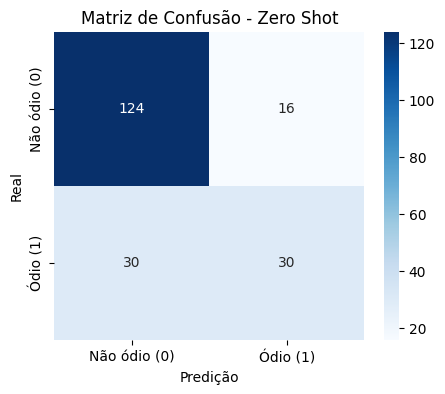


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.81      0.89      0.84       140
           1       0.65      0.50      0.57        60

    accuracy                           0.77       200
   macro avg       0.73      0.69      0.70       200
weighted avg       0.76      0.77      0.76       200



In [17]:
path = '../../../resultados/generativos/gemini/report_zero_shot2.txt'
output_dir = '../../../resultados/generativos/gemini/'
y_true = df_final["label"]
y_pred = df_final["pred_zero_shot"].astype(int)
plot_confusion(y_true, y_pred, "Matriz de Confusão - Zero Shot", path, output_dir)

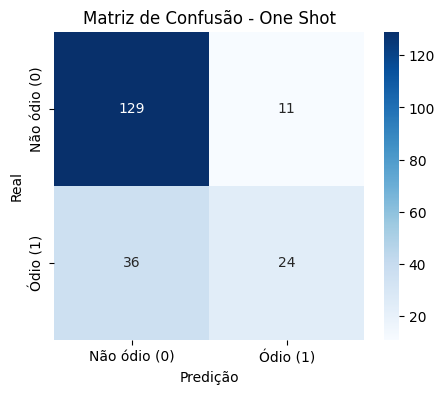


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.78      0.92      0.85       140
           1       0.69      0.40      0.51        60

    accuracy                           0.77       200
   macro avg       0.73      0.66      0.68       200
weighted avg       0.75      0.77      0.74       200



In [18]:
path = '../../../resultados/generativos/gemini/report_one_shot2.txt'
output_dir = '../../../resultados/generativos/gemini/'
y_true = df_final["label"]
y_pred = df_final["pred_one_shot"].astype(int)
plot_confusion(y_true, y_pred, "Matriz de Confusão - One Shot", path, output_dir)

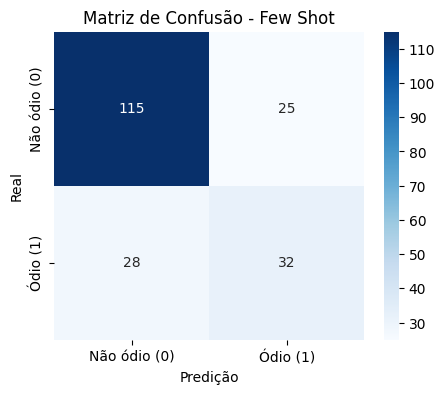


Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.80      0.82      0.81       140
           1       0.56      0.53      0.55        60

    accuracy                           0.73       200
   macro avg       0.68      0.68      0.68       200
weighted avg       0.73      0.73      0.73       200



In [26]:
path = '../../../resultados/generativos/gemini/report_few_shot.txt'
output_dir = '../../../resultados/generativos/gemini/'
y_true = df_final["label"]
y_pred = df_final["pred_few_shot"].astype(int)
plot_confusion(y_true, y_pred, "Matriz de Confusão - Few Shot", path, output_dir)